# Clasificación de celdas Voronoi con ResNet18 (finetuning desde ImageNet)

Finetuning de ResNet18 con pesos `IMAGENET1K_V1` (se reemplaza la capa final por `NUM_CLASES` salidas) para
predecir `ind_cluster`, el índice de la celda de Voronoi (K-Means esférico) de cada imagen. Lee
`train_celdas_balanceado.parquet` y `validation_cluster.parquet`. Función objetivo: **CrossEntropy** (con label
smoothing solo en train); optimizador: **AdamW** con learning rates distintos para la cabeza y el backbone.

Estrategia de finetuning: las primeras `EPOCAS_CABEZA` épocas se entrena solo la cabeza (backbone congelado y con
BatchNorm en modo eval); después se descongela todo. Incluye precisión mixta en CUDA, `ReduceLROnPlateau`, early
stopping según loss de validación y guardado del mejor checkpoint (por loss), el último checkpoint y el historial
por época (con balanced accuracy, por el desbalance de la validación).

Orden: **1. Configuración y datos → 2. Entrenamiento → 3. Métricas sobre validación**.
Además de accuracy top-1/top-5, se reporta el error en km entre la ubicación real y el prototipo (centroide)
de la celda predicha, que es la métrica geográficamente relevante.

## 1. Configuración y datos

In [1]:
from pathlib import Path
from datetime import datetime
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from datasets import Dataset as HFDataset, Image as HFImage
from PIL import Image
from io import BytesIO
from sklearn.metrics import balanced_accuracy_score
from tqdm.auto import tqdm
from IPython.display import display

# Rutas absolutas o relativas a la raíz del proyecto.
RUTA_SAMPLE = "datasets/samples/"
# None: nueva carpeta por ejecución. Para evaluar un modelo previo, indicar su carpeta.
RUTA_RESULTADOS = None
COL_CLUSTER = "ind_cluster"
COLS_COORDENADAS = ["latitude", "longitude"]
RADIO_TIERRA_KM = 6371.0
EPOCAS = 30
EPOCAS_CABEZA = 2  # Primeras épocas con el backbone congelado (solo se entrena la capa final).
BATCH_SIZE = 32  # Si no entra en memoria de GPU: 16 con ACUMULAR_BATCHES = 2.
ACUMULAR_BATCHES = 1  # Batch efectivo: BATCH_SIZE * ACUMULAR_BATCHES.
LR_CABEZA = 1e-3  # Capa final nueva (pesos aleatorios).
LR_BACKBONE = 1e-4  # Capas preentrenadas; probar valores menores si la loss de validación sube pronto.
WEIGHT_DECAY = 1e-2  # AdamW (decaimiento desacoplado).
LABEL_SMOOTHING = 0.1  # Solo en la loss de train; la validación usa CrossEntropy sin suavizado.
PACIENCIA = 4  # Early stopping según loss de validación (no cuenta durante EPOCAS_CABEZA).
TAMANO_IMAGEN = 224
NUM_WORKERS = 0  # Compatible con notebooks en Windows.
SEMILLA = 42
USAR_AMP = True  # Precisión mixta solo con CUDA.
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_NAME = "resnet18_IMAGENET_celdas_balanceado"

raiz = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Ejecutá el notebook dentro del proyecto.")
def resolver_ruta(ruta):
    p = Path(ruta).expanduser()
    return (p if p.is_absolute() else raiz / p).resolve()

ruta_sample = resolver_ruta(RUTA_SAMPLE)
archivos = {"train": ruta_sample / "data" / "train" / "train_celdas_balanceado.parquet",
            "validation": ruta_sample / "data" / "validation" / "validation_cluster.parquet"}
ruta_prototipos = ruta_sample / "data" / "prototipos.csv"
for archivo in (*archivos.values(), ruta_prototipos):
    if not archivo.is_file():
        raise FileNotFoundError(f"{archivo}. Ejecutá preprocessing/celdas_voronoi.ipynb completo.")
assert EPOCAS >= 1 and BATCH_SIZE >= 1 and ACUMULAR_BATCHES >= 1
assert 0 <= EPOCAS_CABEZA < EPOCAS and 0 <= LABEL_SMOOTHING < 1
assert PACIENCIA >= 1 and TAMANO_IMAGEN >= 32 and NUM_WORKERS >= 0
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device(DISPOSITIVO)
amp_activo = USAR_AMP and device.type == "cuda"
ruta_resultados = (resolver_ruta(RUTA_RESULTADOS) if RUTA_RESULTADOS else
                   raiz / "outputs" / MODEL_NAME / datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
print(f"Sample: {ruta_sample}\nResultados: {ruta_resultados}\nDispositivo: {device}")
if device.type == "cuda":
    print(torch.cuda.get_device_name(device))

Sample: C:\Users\juanm\Documents\GitHub\geo-project\datasets\samples
Resultados: c:\Users\juanm\Documents\GitHub\geo-project\outputs\resnet18_IMAGENET_celdas_balanceado\20261025_112715_995629
Dispositivo: cuda
NVIDIA GeForce GTX 1650


### Carga y controles

Las imágenes se decodifican al solicitarlas. Se verifica que no haya imágenes ni panoramas compartidos entre
splits, que `ind_cluster` esté dentro de `[0, K)` con `K` = cantidad de prototipos, y que todas las celdas
tengan ejemplos de train. No se eliminan filas.

In [2]:
import geopandas as gpd

datos = {
    split: HFDataset.from_parquet(str(archivo), cache_dir=str(raiz / ".cache/modeling/hf_celdas"))
        .cast_column("image", HFImage(decode=False))
    for split, archivo in archivos.items()
}
prototipos = pd.read_csv(ruta_prototipos).sort_values(COL_CLUSTER).reset_index(drop=True)
NUM_CLASES = len(prototipos)
assert (prototipos[COL_CLUSTER].to_numpy() == np.arange(NUM_CLASES)).all()
coords_prototipos = prototipos[["lat", "lon"]].to_numpy(dtype=np.float64)

RUTA_PAISES = "src/notebooks/eda/assets/ne_110m_admin_0_countries.geojson"  # Natural Earth, ISO_A2_EH

def completar_country_code(tabla):
    # Completa country_code vacío o nulo con el país cuyo polígono contiene las coordenadas.
    # El mapa es de escala 1:110m: si un punto cae fuera de todo polígono (costa, islas), se usa el más cercano.
    vacios = tabla["country_code"].isna() | (tabla["country_code"].astype("string").str.strip() == "")
    if not vacios.any():
        return tabla
    lat_col, lon_col = COLS_COORDENADAS
    con_coords = vacios & tabla[[lat_col, lon_col]].notna().all(axis=1)

    paises = gpd.read_file(resolver_ruta(RUTA_PAISES)).to_crs("EPSG:4326")
    paises = paises.loc[paises["ISO_A2_EH"] != "-99", ["ISO_A2_EH", "geometry"]]
    puntos = gpd.GeoDataFrame(
        {"fila": tabla.index[con_coords]},
        geometry=gpd.points_from_xy(tabla.loc[con_coords, lon_col], tabla.loc[con_coords, lat_col]),
        crs="EPSG:4326",
    )
    dentro = puntos.sjoin(paises, how="left", predicate="within").drop_duplicates("fila")
    codigos = dentro.set_index("fila")["ISO_A2_EH"]
    sin_pais = codigos.index[codigos.isna()]
    if len(sin_pais):
        # La distancia se mide en un CRS proyectado; alcanza para elegir el polígono más cercano.
        cercanos = (puntos[puntos["fila"].isin(sin_pais)].to_crs("EPSG:3857")
                    .sjoin_nearest(paises.to_crs("EPSG:3857"), how="left").drop_duplicates("fila"))
        codigos.loc[cercanos["fila"].to_numpy()] = cercanos["ISO_A2_EH"].to_numpy()
    tabla = tabla.copy()
    tabla["country_code"] = tabla["country_code"].astype("object")
    tabla.loc[codigos.index, "country_code"] = codigos.to_numpy()
    print(f"country_code completado por coordenadas: {len(codigos):,} de {int(vacios.sum()):,} vacíos")
    return tabla

def metadatos(dataset):
    tabla = dataset.select_columns(["country_code", "panoid", "image_id", *COLS_COORDENADAS, COL_CLUSTER]).to_pandas()
    tabla = completar_country_code(tabla)
    if tabla.isna().any().any():
        raise ValueError("Hay valores faltantes en los metadatos.")
    tabla["country_code"] = tabla["country_code"].str.strip().str.upper()
    if not tabla[COL_CLUSTER].between(0, NUM_CLASES - 1).all():
        raise ValueError(f"{COL_CLUSTER} fuera de [0, {NUM_CLASES}).")
    return tabla

meta_train, meta_val = (metadatos(datos[s]) for s in ("train", "validation"))
if not len(meta_train) or not len(meta_val):
    raise ValueError("Ambos splits deben contener imágenes.")
for columna in ("panoid", "image_id"):
    if set(meta_train[columna]) & set(meta_val[columna]):
        raise ValueError(f"Fuga de datos: {columna} compartidos entre splits.")
conteo = pd.DataFrame({
    "train": meta_train[COL_CLUSTER].value_counts(),
    "validation": meta_val[COL_CLUSTER].value_counts(),
}).reindex(range(NUM_CLASES)).fillna(0).astype(int)
if (conteo["train"] == 0).any():
    raise ValueError(f"Celdas sin ejemplos de train: {conteo.index[conteo['train'] == 0].tolist()}")
print(f"Clases: {NUM_CLASES}; train: {len(meta_train):,}; validación: {len(meta_val):,}")
print(f"Imágenes por celda (train): min {conteo['train'].min()}, mediana {int(conteo['train'].median())}, máx {conteo['train'].max()}")
conteo.T

country_code completado por coordenadas: 198 de 198 vacíos
Clases: 70; train: 19,999; validación: 5,332
Imágenes por celda (train): min 285, mediana 286, máx 286


ind_cluster,0,1,2,3,4,5,6,7,8,9,...,60,61,62,63,64,65,66,67,68,69
train,286,286,286,286,286,286,286,286,286,286,...,285,285,285,285,285,285,285,285,285,285
validation,72,48,20,80,20,64,20,24,512,28,...,52,24,20,120,80,128,128,60,32,16


### Convención de continentes

Agrupación editable de seis continentes, solo para agrupar métricas (no es entrada ni etiqueta).

In [3]:
GRUPOS_CONTINENTES = {
    "África": "BW GH KE NA NG SN ZA LS MG RE RW ST SZ TN UG",
    "América del Norte": "CA CR MX US CW DO GL GT PA PR VI",
    "América del Sur": "AR BO BR CL CO EC PE PY UY",
    "Asia": "BD ID IN JP KH KR KZ LK MN MY NP OM PH TH TR TW VN AE HK IL JO KG LB PS QA SG",
    "Europa": "AT BA BE BG CH CZ DE DK EE ES FI FR GB GR HR HU IE IS IT LT LV NL NO PL PT RO RS RU SE SI SK UA AL AX CY FO LU ME MK",
    "Oceanía": "AU NZ",
}
pais_a_continente = {pais: continente
                     for continente, codigos in GRUPOS_CONTINENTES.items()
                     for pais in codigos.split()}
paises = set(meta_train["country_code"]) | set(meta_val["country_code"])
sin_continente = paises - set(pais_a_continente)
if sin_continente:
    raise ValueError(f"Completá GRUPOS_CONTINENTES para: {sorted(sin_continente)}")

In [4]:
# Media y desvío de ImageNet: los pesos preentrenados esperan esta normalización.
PESOS = models.ResNet18_Weights.IMAGENET1K_V1
MEDIA_IMAGENET, STD_IMAGENET = PESOS.transforms().mean, PESOS.transforms().std

# Augmentation suave solo en train. Sin flip horizontal: altera pistas geográficas (lado de manejo, textos).
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(TAMANO_IMAGEN, scale=(0.6, 1.0)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA_IMAGENET, STD_IMAGENET),
])
transform_val = transforms.Compose([
    transforms.Resize(TAMANO_IMAGEN),
    transforms.CenterCrop(TAMANO_IMAGEN),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA_IMAGENET, STD_IMAGENET),
])

class ImagenesCeldas(Dataset):
    def __init__(self, datos, metadatos, transform):
        self.datos = datos
        self.etiquetas = metadatos[COL_CLUSTER].to_numpy(dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.datos)

    def __getitem__(self, idx):
        contenido = self.datos[int(idx)]["image"]
        if contenido.get("bytes") is not None:
            fuente = BytesIO(contenido["bytes"])
        else:
            fuente = resolver_ruta(contenido["path"])
        with Image.open(fuente) as imagen:
            tensor = self.transform(imagen.convert("RGB"))
        return tensor, int(self.etiquetas[idx])

dataset_train = ImagenesCeldas(datos["train"], meta_train, transform_train)
dataset_val = ImagenesCeldas(datos["validation"], meta_val, transform_val)
loader_train = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEMILLA),
                          num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
loader_val = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")

## 2. Fase de entrenamiento

Finetuning de ResNet18 (`IMAGENET1K_V1`) con la capa final reemplazada por `NUM_CLASES` salidas (logits),
CrossEntropy (con label smoothing en train) y AdamW con dos learning rates: `LR_CABEZA` para la capa nueva y
`LR_BACKBONE` para el resto. Durante las primeras `EPOCAS_CABEZA` épocas el backbone queda congelado y con
BatchNorm en modo eval; esas épocas no mueven el scheduler ni el contador de early stopping. Se reportan loss,
accuracy top-1 y balanced accuracy por época. Se guardan `mejor_resnet18_celdas.pt` (menor loss de validación),
`ultimo_resnet18_celdas.pt` (última época) e `historial.csv`.

In [5]:
def construir_modelo(preentrenado=True):
    # Los pesos de ImageNet traen 1000 clases: se carga la red completa y se reemplaza la capa final.
    m = models.resnet18(weights=PESOS if preentrenado else None)
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASES)
    return m

modelo = construir_modelo().to(device)
backbone_congelado = False

def fijar_backbone(congelado):
    # Congelado: sin gradientes en el backbone (y BatchNorm en eval durante el entrenamiento, ver ejecutar_epoca).
    global backbone_congelado
    backbone_congelado = congelado
    for nombre, p in modelo.named_parameters():
        if not nombre.startswith("fc."):
            p.requires_grad = not congelado

criterio = nn.CrossEntropyLoss()  # Validación y métricas.
criterio_train = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizador = torch.optim.AdamW([
    {"params": modelo.fc.parameters(), "lr": LR_CABEZA},
    {"params": [p for n, p in modelo.named_parameters() if not n.startswith("fc.")], "lr": LR_BACKBONE},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, factor=0.1, patience=2)
scaler = torch.amp.GradScaler("cuda", enabled=amp_activo)
print(f"Parámetros totales: {sum(p.numel() for p in modelo.parameters()):,}; "
      f"capa final: {sum(p.numel() for p in modelo.fc.parameters()):,}")

def ejecutar_epoca(modelo, loader, entrenar):
    modelo.train(entrenar)
    if entrenar and backbone_congelado:
        for nombre, modulo in modelo.named_children():
            if nombre != "fc":
                modulo.eval()  # Conserva las estadísticas de BatchNorm de ImageNet.
    total_loss, aciertos, total = 0.0, 0, 0
    todas_pred, todas_real = [], []
    crit = criterio_train if entrenar else criterio
    if entrenar:
        optimizador.zero_grad(set_to_none=True)
    with torch.set_grad_enabled(entrenar):
        for paso, (imagenes, etiquetas) in enumerate(tqdm(loader, desc="Train" if entrenar else "Validación")):
            imagenes = imagenes.to(device, non_blocking=True)
            etiquetas = etiquetas.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=amp_activo):
                logits = modelo(imagenes)
                loss = crit(logits.float(), etiquetas)
            n = etiquetas.size(0)
            if entrenar:
                # Ponderar por imágenes, incluso en el último grupo incompleto.
                inicio_grupo = (paso // ACUMULAR_BATCHES) * ACUMULAR_BATCHES
                n_grupo = min(ACUMULAR_BATCHES * loader.batch_size,
                              len(loader.dataset) - inicio_grupo * loader.batch_size)
                scaler.scale(loss * n / n_grupo).backward()
                if (paso + 1) % ACUMULAR_BATCHES == 0 or paso + 1 == len(loader):
                    scaler.step(optimizador)
                    scaler.update()
                    optimizador.zero_grad(set_to_none=True)
            pred_batch = logits.argmax(dim=1)
            total_loss += loss.detach().item() * n
            aciertos += (pred_batch == etiquetas).sum().item()
            total += n
            todas_pred.append(pred_batch.cpu())
            todas_real.append(etiquetas.cpu())
    acc_balanceada = balanced_accuracy_score(torch.cat(todas_real).numpy(), torch.cat(todas_pred).numpy())
    return total_loss / total, aciertos / total, acc_balanceada

Parámetros totales: 11,212,422; capa final: 35,910


In [6]:
ruta_resultados.mkdir(parents=True, exist_ok=True)
ruta_checkpoint = ruta_resultados / "mejor_resnet18_celdas.pt"
ruta_ultimo = ruta_resultados / "ultimo_resnet18_celdas.pt"
if ruta_checkpoint.exists():
    raise FileExistsError("Ya existe un modelo en esta carpeta. Usá otra RUTA_RESULTADOS para entrenar.")
config_entrenamiento = {
    "arquitectura": "resnet18", "tarea": "clasificacion_celdas_voronoi", "weights": "IMAGENET1K_V1",
    "modo": "finetuning", "epocas_cabeza": EPOCAS_CABEZA,
    "ruta_sample": str(ruta_sample), "num_clases": NUM_CLASES, "columna_etiqueta": COL_CLUSTER,
    "epocas_maximas": EPOCAS, "batch_size": BATCH_SIZE, "acumular_batches": ACUMULAR_BATCHES,
    "lr_cabeza": LR_CABEZA, "lr_backbone": LR_BACKBONE, "optimizador": "AdamW", "weight_decay": WEIGHT_DECAY,
    "loss": "CrossEntropy", "label_smoothing_train": LABEL_SMOOTHING,
    "paciencia": PACIENCIA, "tamano_imagen": TAMANO_IMAGEN, "semilla": SEMILLA,
    "amp": amp_activo, "pais_a_continente": pais_a_continente,
    "preprocesamiento_train": repr(transform_train), "preprocesamiento_val": repr(transform_val),
    "filas_train": len(dataset_train), "filas_validation": len(dataset_val),
    "torch": str(torch.__version__), "dispositivo": str(device),
}
(ruta_resultados / "config_entrenamiento.json").write_text(
    json.dumps(config_entrenamiento, ensure_ascii=False, indent=2), encoding="utf-8")
prototipos.to_csv(ruta_resultados / "prototipos.csv", index=False)  # para usar el modelo sin el sample

def guardar(ruta, epoca, loss_val, acc_val):
    torch.save({"model_state_dict": modelo.state_dict(), "epoca": epoca, "loss_validation": loss_val,
                "accuracy_validation": acc_val, "config": config_entrenamiento}, ruta)

historial = []
mejor_loss, sin_mejora = float("inf"), 0
for epoca in range(1, EPOCAS + 1):
    inicio = time.perf_counter()
    solo_cabeza = epoca <= EPOCAS_CABEZA
    fijar_backbone(solo_cabeza)
    lr_cabeza, lr_backbone = (g["lr"] for g in optimizador.param_groups)
    loss_train, acc_train, bal_train = ejecutar_epoca(modelo, loader_train, entrenar=True)
    loss_val, acc_val, bal_val = ejecutar_epoca(modelo, loader_val, entrenar=False)
    if not np.isfinite([loss_train, loss_val]).all():
        raise RuntimeError("Loss no finita. Revisá los learning rates y los datos.")
    historial.append({"epoca": epoca, "fase": "cabeza" if solo_cabeza else "completo",
                      "loss_train": loss_train, "accuracy_train": acc_train, "balanced_accuracy_train": bal_train,
                      "loss_validation": loss_val, "accuracy_validation": acc_val, "balanced_accuracy_validation": bal_val,
                      "lr_cabeza": lr_cabeza, "lr_backbone": lr_backbone, "segundos": time.perf_counter() - inicio})
    pd.DataFrame(historial).to_csv(ruta_resultados / "historial.csv", index=False)
    guardar(ruta_ultimo, epoca, loss_val, acc_val)
    if loss_val < mejor_loss:
        mejor_loss, sin_mejora = loss_val, 0
        guardar(ruta_checkpoint, epoca, loss_val, acc_val)
    elif not solo_cabeza:
        sin_mejora += 1
    if not solo_cabeza:
        scheduler.step(loss_val)
    print(f"Época {epoca}/{EPOCAS} [{'cabeza' if solo_cabeza else 'completo'}] "
          f"| train loss={loss_train:.4f} acc={acc_train:.3f} "
          f"| val loss={loss_val:.4f} acc={acc_val:.3f} bal={bal_val:.3f} "
          f"| lr cabeza={lr_cabeza:.5g} backbone={lr_backbone:.5g}")
    if sin_mejora >= PACIENCIA:
        print(f"Early stopping: {PACIENCIA} épocas sin mejora.")
        break
print(f"Mejor loss de validación: {mejor_loss:.4f}; checkpoint: {ruta_checkpoint}")

Train:   0%|          | 0/625 [00:00<?, ?it/s]

Validación:   0%|          | 0/167 [00:00<?, ?it/s]

Época 1/30 [cabeza] | train loss=3.8531 acc=0.105 | val loss=3.5398 acc=0.119 bal=0.157 | lr cabeza=0.001 backbone=0.0001


Train:   0%|          | 0/625 [00:00<?, ?it/s]

Validación:   0%|          | 0/167 [00:00<?, ?it/s]

...

Validación:   0%|          | 0/167 [00:00<?, ?it/s]

Época 9/30 [completo] | train loss=1.6849 acc=0.715 | val loss=2.7844 acc=0.273 bal=0.354 | lr cabeza=0.001 backbone=0.0001


Train:   0%|          | 0/625 [00:00<?, ?it/s]

Validación:   0%|          | 0/167 [00:00<?, ?it/s]

Época 10/30 [completo] | train loss=1.3156 acc=0.881 | val loss=2.4360 acc=0.344 bal=0.415 | lr cabeza=0.0001 backbone=1e-05
Early stopping: 4 épocas sin mejora.
Mejor loss de validación: 2.3948; checkpoint: c:\Users\juanm\Documents\GitHub\geo-project\outputs\resnet18_IMAGENET_celdas_balanceado\20261025_112715_995629\mejor_resnet18_celdas.pt


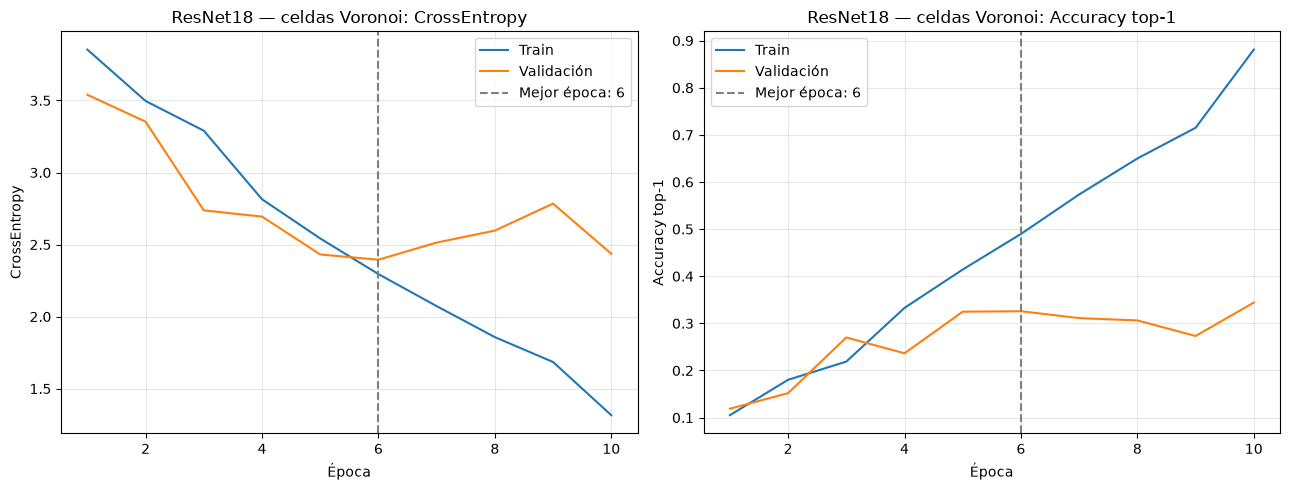

In [7]:
historia = pd.read_csv(ruta_resultados / "historial.csv")
mejor_epoca = int(historia.loc[historia["loss_validation"].idxmin(), "epoca"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (columna, titulo) in zip(axes, [("loss", "CrossEntropy"), ("accuracy", "Accuracy top-1")]):
    ax.plot(historia["epoca"], historia[f"{columna}_train"], label="Train")
    ax.plot(historia["epoca"], historia[f"{columna}_validation"], label="Validación")
    ax.axvline(mejor_epoca, color="gray", linestyle="--", label=f"Mejor época: {mejor_epoca}")
    ax.set(xlabel="Época", ylabel=titulo, title=f"ResNet18 — celdas Voronoi: {titulo}")
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ruta_resultados / "curvas_entrenamiento.png", dpi=160)
plt.show()

## 3. Métricas sobre validación

Se recarga el mejor checkpoint y se evalúa todo el split de validación. Para evaluar una corrida anterior sin
entrenar, indicar su carpeta en `RUTA_RESULTADOS`, ejecutar la sección 1 y luego esta sección.

- **Accuracy top-1 y top-5** sobre `ind_cluster`.
- **Error en km** (Haversine) entre la ubicación real y el prototipo de la celda predicha; también el error
  que resultaría de predecir siempre la celda correcta (cota inferior del esquema de celdas).
- Resultados globales y por continente real, y métricas por celda.

Como validación también selecciona el checkpoint, estas métricas no reemplazan un test independiente.

In [8]:
checkpoint = torch.load(ruta_resultados / "mejor_resnet18_celdas.pt", map_location="cpu", weights_only=True)
cfg = checkpoint["config"]
if (cfg["arquitectura"] != "resnet18" or cfg.get("tarea") != "clasificacion_celdas_voronoi"
        or cfg["num_clases"] != NUM_CLASES or cfg["tamano_imagen"] != TAMANO_IMAGEN
        or cfg["preprocesamiento_val"] != repr(transform_val)):
    raise ValueError("La configuración de evaluación no coincide con el entrenamiento.")
if "optimizador" in globals():
    optimizador.state.clear()
if "modelo" not in globals():
    modelo = construir_modelo(preentrenado=False).to(device)  # Los pesos salen del checkpoint.
modelo.load_state_dict(checkpoint["model_state_dict"])
print(f"Evaluando época {checkpoint['epoca']} (loss val={checkpoint['loss_validation']:.4f}, acc={checkpoint['accuracy_validation']:.3f})")
del checkpoint
modelo.eval()
salidas = []
with torch.inference_mode():
    for imagenes, _ in tqdm(loader_val, desc="Métricas de validación"):
        with torch.autocast(device_type=device.type, enabled=amp_activo):
            logits = modelo(imagenes.to(device, non_blocking=True))
        salidas.append(logits.float().cpu())
logits = torch.cat(salidas)
assert logits.shape == (len(dataset_val), NUM_CLASES) and len(meta_val) == len(dataset_val)
probs = torch.softmax(logits, dim=1)
top5 = probs.topk(min(5, NUM_CLASES), dim=1).indices.numpy()
pred = top5[:, 0]
real = meta_val[COL_CLUSTER].to_numpy()

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.deg2rad, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * RADIO_TIERRA_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

lat_real, lon_real = (meta_val[c].to_numpy(dtype=np.float64) for c in COLS_COORDENADAS)
predicciones = meta_val[["image_id", "panoid", "country_code", *COLS_COORDENADAS]].copy()
predicciones["cluster_real"] = real
predicciones["cluster_predicho"] = pred
predicciones["prob_predicha"] = probs.max(dim=1).values.numpy()
predicciones["acierto_top1"] = pred == real
predicciones["acierto_top5"] = (top5 == real[:, None]).any(axis=1)
predicciones["error_km"] = haversine_km(lat_real, lon_real, coords_prototipos[pred, 0], coords_prototipos[pred, 1])
predicciones["error_km_cota"] = haversine_km(lat_real, lon_real, coords_prototipos[real, 0], coords_prototipos[real, 1])
predicciones["continente_real"] = predicciones["country_code"].map(pais_a_continente)

resumen_metricas = {
    "n_validation": len(predicciones),
    "loss_validation": float(criterio(logits, torch.from_numpy(real.astype(np.int64))).item()),
    "accuracy_top1": float(predicciones["acierto_top1"].mean()),
    "accuracy_top5": float(predicciones["acierto_top5"].mean()),
    "error_medio_km": float(predicciones["error_km"].mean()),
    "error_mediano_km": float(predicciones["error_km"].median()),
    "error_medio_km_cota_celdas": float(predicciones["error_km_cota"].mean()),
}
display(pd.Series(resumen_metricas, name="Validación").to_frame())
por_continente = predicciones.groupby("continente_real").agg(
    n=("error_km", "size"), accuracy_top1=("acierto_top1", "mean"), accuracy_top5=("acierto_top5", "mean"),
    error_medio_km=("error_km", "mean"), error_mediano_km=("error_km", "median"))
display(por_continente)
por_celda = predicciones.groupby("cluster_real").agg(
    n=("acierto_top1", "size"), accuracy_top1=("acierto_top1", "mean"), error_medio_km=("error_km", "mean"))
predicciones.to_csv(ruta_resultados / "predicciones_validation.csv", index=False)
por_continente.to_csv(ruta_resultados / "metricas_por_continente.csv")
por_celda.to_csv(ruta_resultados / "metricas_por_celda.csv")
(ruta_resultados / "metricas_validation.json").write_text(
    json.dumps(resumen_metricas, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

Evaluando época 6 (loss val=2.3948, acc=0.326)


Métricas de validación:   0%|          | 0/167 [00:00<?, ?it/s]

,Validación
n_validation,5332.000000
loss_validation,2.394828
accuracy_top1,0.325769
accuracy_top5,0.698987
error_medio_km,3788.412033
error_mediano_km,1212.593232
error_medio_km_cota_celdas,441.080398


,n,accuracy_top1,accuracy_top5,error_medio_km,error_mediano_km
continente_real,,,,,
América del Norte,1500,0.280667,0.619333,4875.203452,2969.752865
América del Sur,580,0.315517,0.724138,3982.618692,1364.206581
Asia,1432,0.400838,0.795391,3450.535747,944.628882
Europa,1460,0.252055,0.648630,2808.340669,979.225842
Oceanía,180,0.383333,0.705556,6275.059155,2056.891323
África,180,0.677778,0.916667,2256.854031,430.793341


277

### Gráficos de validación

Matriz de confusión entre celdas (normalizada por fila) y distribución del error en km.

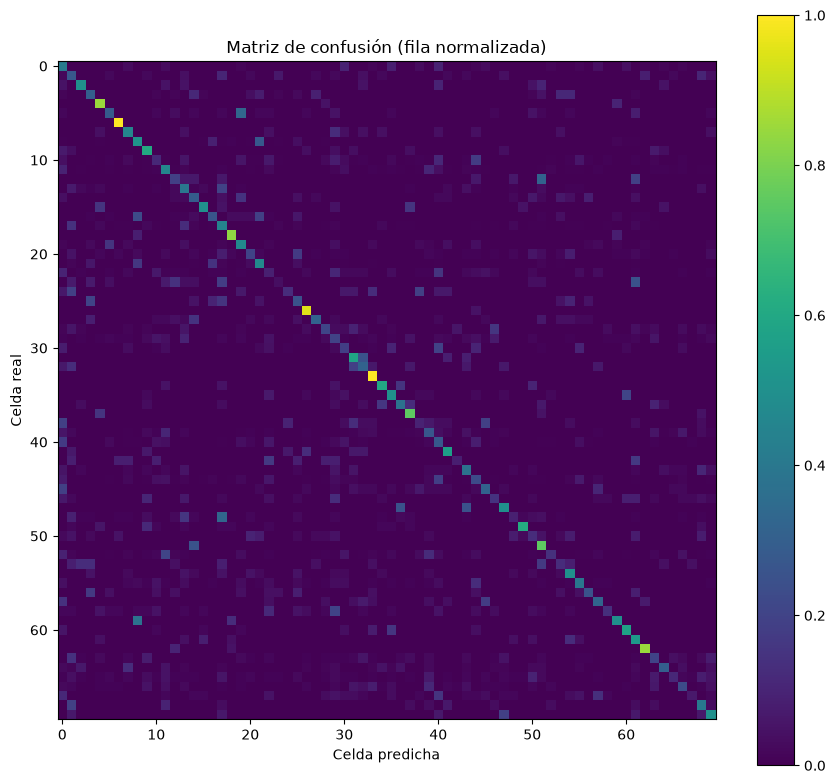

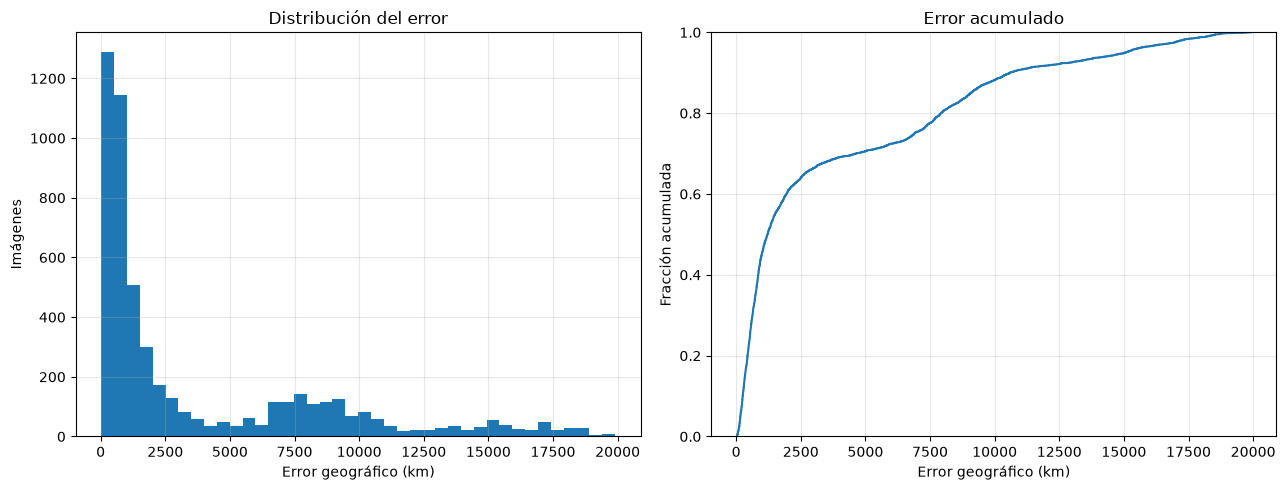

Resultados guardados en c:\Users\juanm\Documents\GitHub\geo-project\outputs\resnet18_IMAGENET_celdas_balanceado\20261025_112715_995629


In [9]:
matriz = np.zeros((NUM_CLASES, NUM_CLASES))
np.add.at(matriz, (real, pred), 1)
matriz = matriz / np.maximum(matriz.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(matriz, cmap="viridis", vmin=0, vmax=1)
ax.set(xlabel="Celda predicha", ylabel="Celda real", title="Matriz de confusión (fila normalizada)")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(ruta_resultados / "matriz_confusion.png", dpi=160)
plt.show()

errores = np.sort(predicciones["error_km"].to_numpy())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(errores, bins=40)
axes[0].set(xlabel="Error geográfico (km)", ylabel="Imágenes", title="Distribución del error")
axes[1].step(errores, np.arange(1, len(errores) + 1) / len(errores), where="post")
axes[1].set(xlabel="Error geográfico (km)", ylabel="Fracción acumulada", title="Error acumulado", ylim=(0, 1))
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ruta_resultados / "distribucion_error_km.png", dpi=160)
plt.show()
print(f"Resultados guardados en {ruta_resultados}")

## 4. Métricas adicionales de clasificación

Usan `real`, `pred`, `probs` y `predicciones` de la sección 3. Por el desbalance entre celdas, además de la
accuracy global se reportan **balanced accuracy** (media del recall por celda) y **F1 macro** (todas las celdas
pesan igual), junto con **F1 ponderado** (pesa por cantidad de imágenes).

In [10]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             cohen_kappa_score, f1_score, precision_score, recall_score)

resumen_extra = {
    "accuracy_top1": accuracy_score(real, pred),
    "balanced_accuracy": balanced_accuracy_score(real, pred),
    "precision_macro": precision_score(real, pred, average="macro", zero_division=0),
    "recall_macro": recall_score(real, pred, average="macro", zero_division=0),
    "f1_macro": f1_score(real, pred, average="macro", zero_division=0),
    "f1_ponderado": f1_score(real, pred, average="weighted", zero_division=0),
    "cohen_kappa": cohen_kappa_score(real, pred),
    "baseline_celda_mayoritaria": float(np.bincount(meta_train[COL_CLUSTER], minlength=NUM_CLASES).max() / len(meta_train)),
    "baseline_azar": 1 / NUM_CLASES,
}
display(pd.Series(resumen_extra, name="Validación").to_frame())

reporte = pd.DataFrame(classification_report(real, pred, labels=range(NUM_CLASES), output_dict=True, zero_division=0)).T
reporte_celdas = reporte.iloc[:NUM_CLASES].copy()
reporte_celdas.index = reporte_celdas.index.astype(int)
reporte_celdas.index.name = COL_CLUSTER
reporte_celdas["n_train"] = conteo["train"]
display(reporte_celdas.sort_values("f1-score", ascending=False).round(3))
reporte_celdas.to_csv(ruta_resultados / "reporte_clasificacion_por_celda.csv")
(ruta_resultados / "metricas_extra_validation.json").write_text(
    json.dumps({k: float(v) for k, v in resumen_extra.items()}, indent=2), encoding="utf-8")

,Validación
accuracy_top1,0.325769
balanced_accuracy,0.383771
precision_macro,0.306430
recall_macro,0.383771
f1_macro,0.298778
f1_ponderado,0.331728
cohen_kappa,0.307129
baseline_celda_mayoritaria,0.014301
baseline_azar,0.014286


,precision,recall,f1-score,support,n_train
ind_cluster,,,,,
6,0.667,1.000,0.800,20.0,286
49,0.842,0.615,0.711,52.0,286
62,0.567,0.850,0.680,20.0,285
8,0.821,0.512,0.631,512.0,286
26,0.452,0.950,0.613,20.0,286
...,...,...,...,...,...
25,0.060,0.250,0.096,20.0,286
51,0.050,0.750,0.094,4.0,285
38,0.091,0.094,0.092,32.0,286


370

### Accuracy top-k

Fracción de imágenes cuya celda real está entre las `k` más probables. Útil porque celdas vecinas suelen ser
confundibles.

k,1,2,3,4,5,6,7,8,9,10
accuracy,0.326,0.491,0.585,0.649,0.699,0.737,0.769,0.798,0.82,0.841


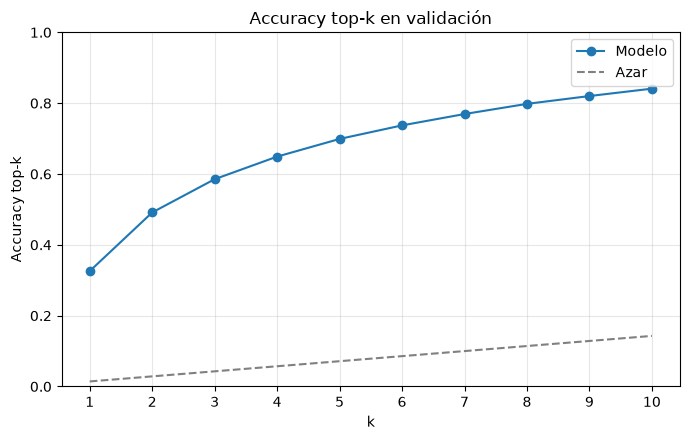

In [11]:
KS = list(range(1, min(10, NUM_CLASES) + 1))
orden = probs.argsort(dim=1, descending=True).numpy()
acc_topk = pd.Series({k: float((orden[:, :k] == real[:, None]).any(axis=1).mean()) for k in KS}, name="accuracy")
acc_topk.index.name = "k"
display(acc_topk.to_frame().T.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(acc_topk.index, acc_topk.values, marker="o", label="Modelo")
ax.plot(KS, [k / NUM_CLASES for k in KS], "--", color="gray", label="Azar")
ax.set(xlabel="k", ylabel="Accuracy top-k", title="Accuracy top-k en validación", ylim=(0, 1))
ax.set_xticks(KS)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ruta_resultados / "accuracy_topk.png", dpi=160)
plt.show()

### Matriz de confusión con conteos

La matriz de la sección 3 está normalizada por fila (recall por celda). Acá se muestra con **conteos absolutos**
(escala logarítmica) y, abajo, normalizada por **columna** (precisión: de lo que el modelo dice que es la celda
*j*, qué fracción lo es de verdad).

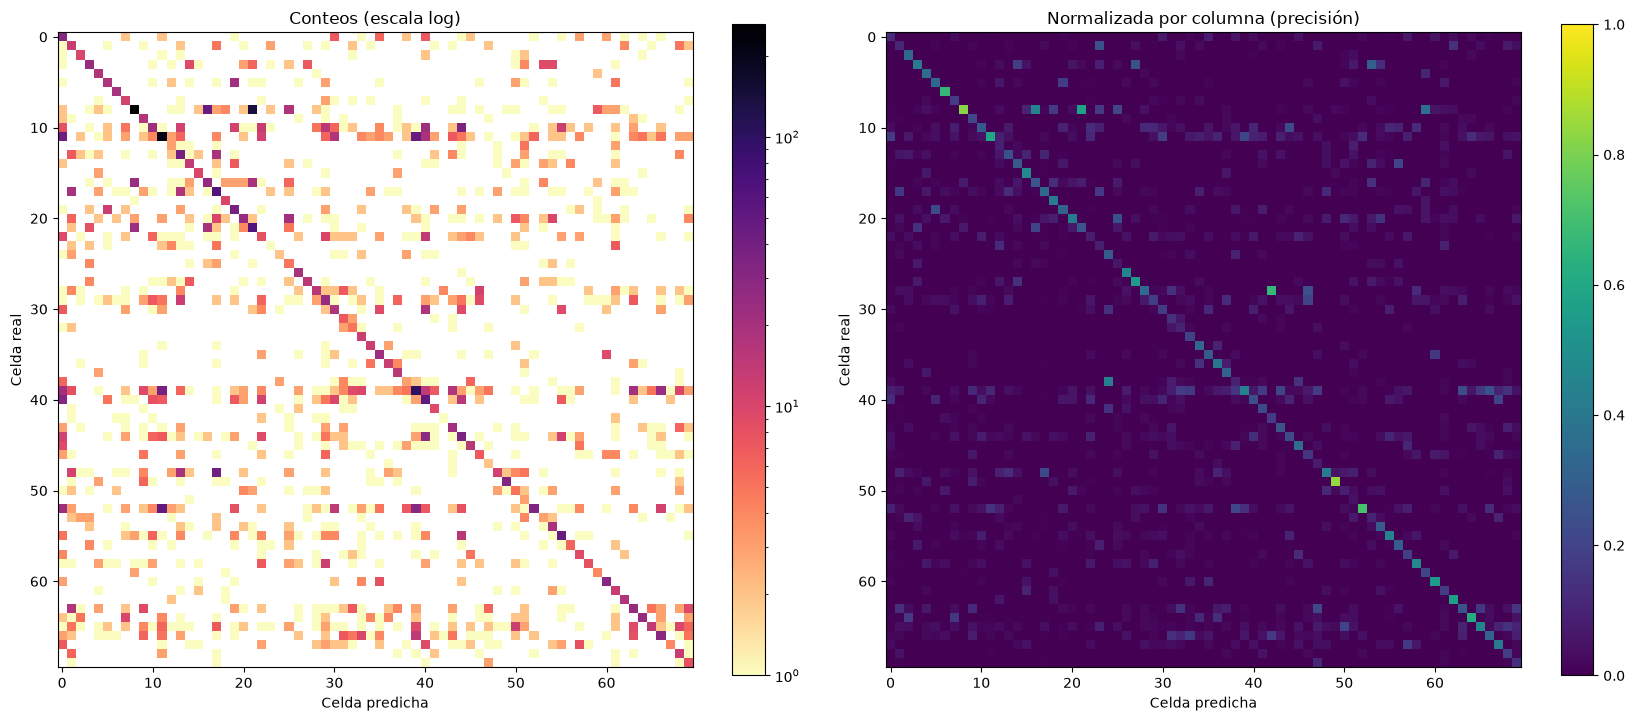

,celda_real,celda_predicha,n,pct_de_la_celda_real,distancia_prototipos_km
0,8,21,140,0.273,992.0
1,52,11,50,0.205,1275.0
2,11,39,47,0.103,1336.0
3,8,16,45,0.088,1874.0
4,11,0,43,0.094,7764.0
5,48,17,41,0.331,1327.0
6,39,11,38,0.104,1336.0
7,10,44,35,0.175,556.0
8,40,0,31,0.168,928.0
9,52,39,30,0.123,1640.0


In [12]:
conteos_mc = np.zeros((NUM_CLASES, NUM_CLASES), dtype=int)
np.add.at(conteos_mc, (real, pred), 1)
por_columna = conteos_mc / np.maximum(conteos_mc.sum(axis=0, keepdims=True), 1)
pd.DataFrame(conteos_mc).to_csv(ruta_resultados / "matriz_confusion_conteos.csv", index_label="real")

from matplotlib.colors import LogNorm
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
im0 = axes[0].imshow(conteos_mc + 0.0, cmap="magma_r", norm=LogNorm(vmin=1, vmax=max(conteos_mc.max(), 2)))
axes[0].set(xlabel="Celda predicha", ylabel="Celda real", title="Conteos (escala log)")
fig.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(por_columna, cmap="viridis", vmin=0, vmax=1)
axes[1].set(xlabel="Celda predicha", ylabel="Celda real", title="Normalizada por columna (precisión)")
fig.colorbar(im1, ax=axes[1])
fig.tight_layout()
fig.savefig(ruta_resultados / "matriz_confusion_conteos.png", dpi=160)
plt.show()

# Confusiones más frecuentes fuera de la diagonal, con la distancia entre prototipos.
fuera = conteos_mc.copy()
np.fill_diagonal(fuera, 0)
r, c = np.unravel_index(np.argsort(fuera, axis=None)[::-1][:15], fuera.shape)
top_confusiones = pd.DataFrame({
    "celda_real": r, "celda_predicha": c, "n": fuera[r, c],
    "pct_de_la_celda_real": (fuera[r, c] / conteos_mc.sum(axis=1)[r]).round(3),
    "distancia_prototipos_km": haversine_km(coords_prototipos[r, 0], coords_prototipos[r, 1],
                                            coords_prototipos[c, 0], coords_prototipos[c, 1]).round(0),
})
display(top_confusiones[top_confusiones["n"] > 0])
top_confusiones.to_csv(ruta_resultados / "top_confusiones.csv", index=False)

### Rendimiento por celda

Accuracy (recall) por celda según su tamaño de train: sirve para ver si el modelo sólo acierta las celdas
grandes.

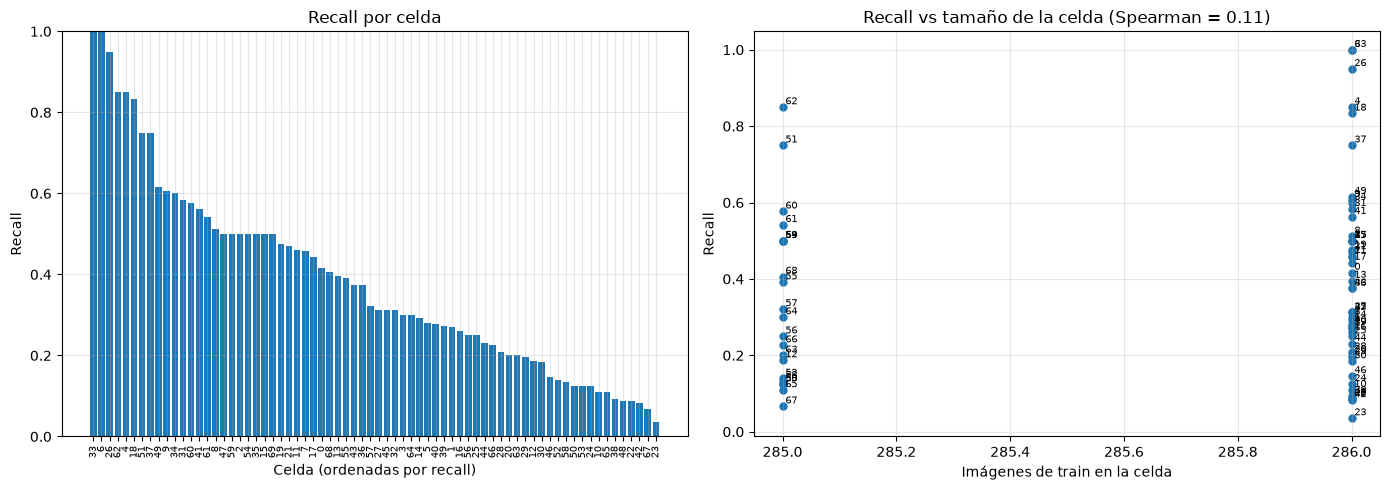

In [13]:
tabla_celdas = reporte_celdas[["precision", "recall", "f1-score", "support", "n_train"]].copy()
tabla_celdas["error_medio_km"] = por_celda["error_medio_km"]
corr = tabla_celdas[["recall", "n_train"]].corr(method="spearman").iloc[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
orden_celdas = tabla_celdas["recall"].sort_values(ascending=False).index
axes[0].bar(range(NUM_CLASES), tabla_celdas.loc[orden_celdas, "recall"], color="#1f77b4")
axes[0].set_xticks(range(NUM_CLASES))
axes[0].set_xticklabels(orden_celdas, rotation=90, fontsize=7)
axes[0].set(xlabel="Celda (ordenadas por recall)", ylabel="Recall", title="Recall por celda", ylim=(0, 1))
axes[1].scatter(tabla_celdas["n_train"], tabla_celdas["recall"], s=25)
for celda, fila in tabla_celdas.iterrows():
    axes[1].annotate(str(celda), (fila["n_train"], fila["recall"]), fontsize=7, xytext=(2, 2), textcoords="offset points")
axes[1].set(xlabel="Imágenes de train en la celda", ylabel="Recall",
            title=f"Recall vs tamaño de la celda (Spearman = {corr:.2f})")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ruta_resultados / "rendimiento_por_celda.png", dpi=160)
plt.show()

### Mapa de rendimiento por celda

Cada prototipo se colorea por su recall en validación; el tamaño indica la cantidad de imágenes de validación.

In [14]:
import plotly.graph_objects as go

fig = go.Figure(go.Scattergeo(
    lat=prototipos["lat"], lon=prototipos["lon"], mode="markers+text", text=prototipos[COL_CLUSTER].astype(str),
    textposition="top center",
    marker=dict(size=8 + 20 * tabla_celdas["support"] / tabla_celdas["support"].max(),
                color=tabla_celdas["recall"], colorscale="RdYlGn", cmin=0, cmax=1,
                colorbar=dict(title="Recall"), line=dict(width=0.5, color="black")),
    customdata=np.column_stack([tabla_celdas["support"], tabla_celdas["precision"], tabla_celdas["error_medio_km"]]),
    hovertemplate=("Celda %{text}<br>Recall %{marker.color:.2f}<br>Precisión %{customdata[1]:.2f}"
                   "<br>N val %{customdata[0]:.0f}<br>Error medio %{customdata[2]:.0f} km<extra></extra>")))
fig.update_geos(projection_type="natural earth", showland=True, landcolor="#f1ede4", showocean=True,
                oceancolor="#dfeaf2", showcountries=True, countrycolor="#bbbbbb", showcoastlines=True, coastlinecolor="#888888")
fig.update_layout(title="Recall en validación por celda de Voronoi", height=600, margin=dict(l=0, r=0, t=50, b=0))
fig.show()

### Rendimiento por país

Accuracy top-1, top-5 y error en km por país real, ordenado por error medio.

,n,accuracy_top1,accuracy_top5,error_medio_km,error_mediano_km,error_medio_km_cota
country_code,,,,,,
IS,20,0.950,0.950,253.921,130.269,155.977
OM,20,1.000,1.000,296.903,239.540,296.903
BW,20,0.900,1.000,674.056,430.793,363.089
SN,20,0.850,1.000,685.733,179.642,163.667
NP,20,0.250,0.900,1001.288,585.722,381.954
...,...,...,...,...,...,...
TH,132,0.220,0.621,7387.680,2463.686,280.764
MX,116,0.060,0.319,7697.755,7224.092,394.586
PE,24,0.292,0.667,8004.974,4538.544,414.633


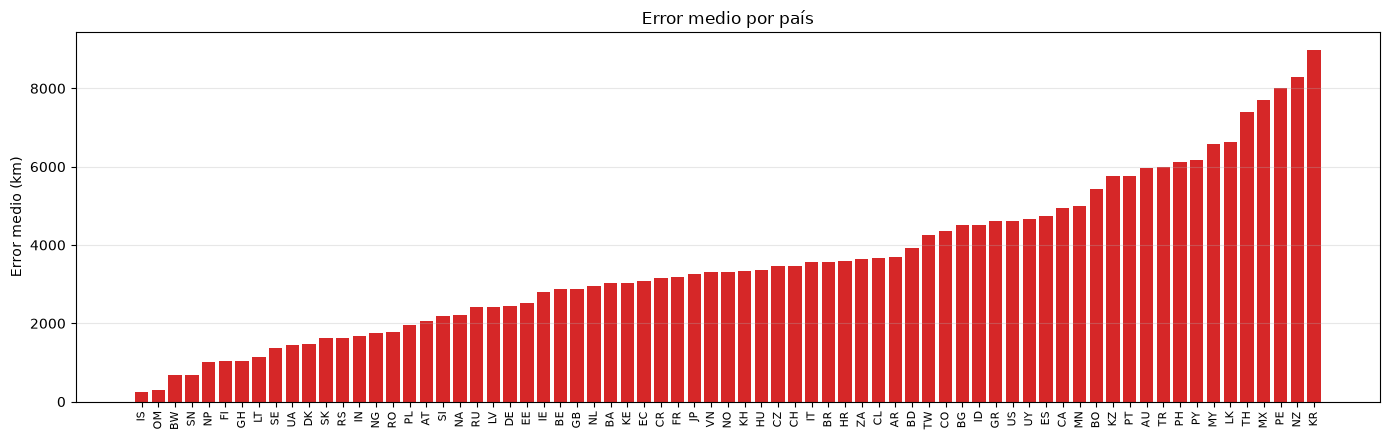

In [15]:
por_pais = predicciones.groupby("country_code").agg(
    n=("error_km", "size"), accuracy_top1=("acierto_top1", "mean"), accuracy_top5=("acierto_top5", "mean"),
    error_medio_km=("error_km", "mean"), error_mediano_km=("error_km", "median"),
    error_medio_km_cota=("error_km_cota", "mean")).sort_values("error_medio_km")
por_pais.to_csv(ruta_resultados / "metricas_por_pais.csv")
display(por_pais.round(3))

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(por_pais.index, por_pais["error_medio_km"], color="#d62728")
ax.set(ylabel="Error medio (km)", title="Error medio por país")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(ruta_resultados / "error_por_pais.png", dpi=160)
plt.show()

### Calibración de la confianza

Compara la probabilidad que el modelo asigna a su predicción con la accuracy real. Una curva por debajo de la
diagonal indica sobreconfianza. ECE = diferencia media ponderada entre confianza y accuracy por bin.

ECE = 0.0682


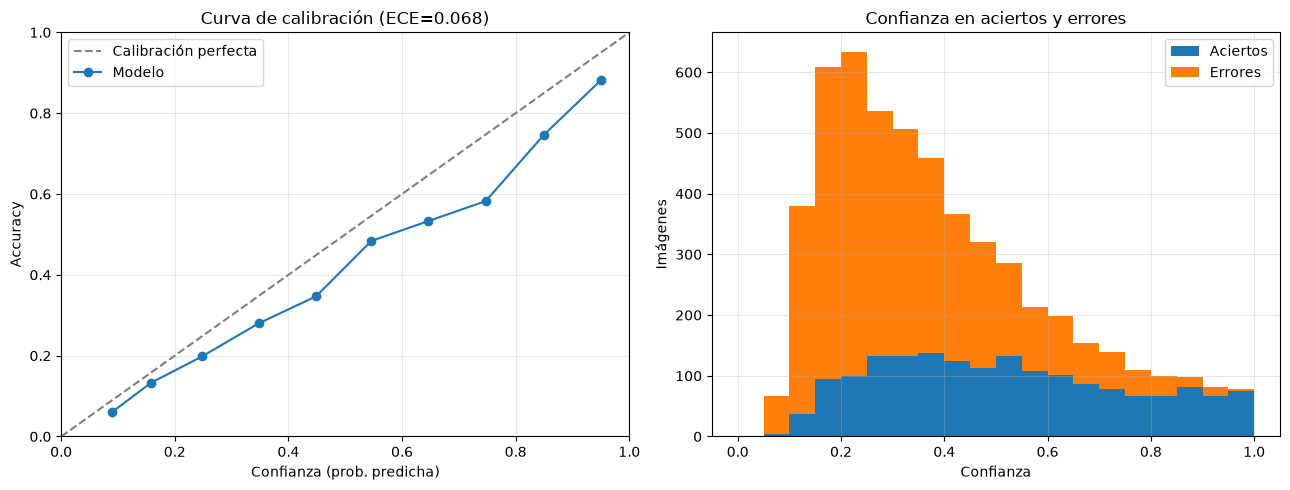

In [16]:
conf = predicciones["prob_predicha"].to_numpy()
acierto = predicciones["acierto_top1"].to_numpy()
bordes = np.linspace(0, 1, 11)
bin_id = np.clip(np.digitize(conf, bordes[1:-1]), 0, 9)
calib = pd.DataFrame({
    "conf_media": [conf[bin_id == b].mean() if (bin_id == b).any() else np.nan for b in range(10)],
    "accuracy": [acierto[bin_id == b].mean() if (bin_id == b).any() else np.nan for b in range(10)],
    "n": [(bin_id == b).sum() for b in range(10)],
})
ece = float(np.nansum(calib["n"] / calib["n"].sum() * (calib["accuracy"] - calib["conf_media"]).abs()))
print(f"ECE = {ece:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
axes[0].plot(calib["conf_media"], calib["accuracy"], marker="o", label="Modelo")
axes[0].set(xlabel="Confianza (prob. predicha)", ylabel="Accuracy", title=f"Curva de calibración (ECE={ece:.3f})",
            xlim=(0, 1), ylim=(0, 1))
axes[0].legend()
axes[1].hist([conf[acierto], conf[~acierto]], bins=20, range=(0, 1), label=["Aciertos", "Errores"], stacked=True)
axes[1].set(xlabel="Confianza", ylabel="Imágenes", title="Confianza en aciertos y errores")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ruta_resultados / "calibracion.png", dpi=160)
plt.show()

### Mapa de errores

Muestra de imágenes de validación: cada línea une la ubicación real con el prototipo predicho. Se resaltan en
rojo los errores de más de 3000 km.

In [17]:
N_MAPA = 40
UMBRAL_KM = 3000
rng = np.random.default_rng(SEMILLA)
errores_idx = np.where(~predicciones["acierto_top1"].to_numpy())[0]
idx = rng.choice(errores_idx, min(N_MAPA, len(errores_idx)), replace=False)

fig = go.Figure()
for grupo, color, nombre in ((predicciones["error_km"].to_numpy()[idx] > UMBRAL_KM, "#d62728", f"> {UMBRAL_KM} km"),
                             (predicciones["error_km"].to_numpy()[idx] <= UMBRAL_KM, "#7f7f7f", f"<= {UMBRAL_KM} km")):
    sel = idx[grupo]
    lats, lons = [], []
    for i in sel:
        p = pred[i]
        lats += [lat_real[i], coords_prototipos[p, 0], None]
        lons += [lon_real[i], coords_prototipos[p, 1], None]
    fig.add_trace(go.Scattergeo(lat=lats, lon=lons, mode="lines", line=dict(width=0.7, color=color),
                                opacity=0.6, name=nombre))
fig.add_trace(go.Scattergeo(lat=lat_real[idx], lon=lon_real[idx], mode="markers", marker=dict(size=3, color="black"),
                            name="ubicación real"))
fig.add_trace(go.Scattergeo(lat=prototipos["lat"], lon=prototipos["lon"], mode="markers",
                            marker=dict(size=6, color="blue", symbol="x"), name="prototipos"))
fig.update_geos(projection_type="natural earth", showland=True, landcolor="#f1ede4", showocean=True,
                oceancolor="#dfeaf2", showcountries=True, countrycolor="#bbbbbb", showcoastlines=True, coastlinecolor="#888888")
fig.update_layout(title=f"Errores de clasificación ({len(idx)} imágenes de validación al azar)", height=600,
                  margin=dict(l=0, r=0, t=50, b=0), legend=dict(x=0.01, y=0.01))
fig.show()

Apliqué los diez cambios en cell_classifier_finetune.ipynb. No ejecuté nada, así que conviene correr desde la sección 1.

- Normalización (1): train y validación usan la media y el desvío de ImageNet, tomados de ResNet18_Weights.IMAGENET1K_V1.

- Cabeza (2): una función construir_modelo() carga la red completa con sus 1000 clases y reemplaza fc por una capa de NUM_CLASES salidas.

- Registro (3): el config guarda weights: IMAGENET1K_V1, modo, epocas_cabeza, lr_cabeza, lr_backbone, AdamW y label_smoothing_train. La celda de evaluación arma el modelo de respaldo con construir_modelo(preentrenado=False).

- Batch (4): BATCH_SIZE=32 y ACUMULAR_BATCHES=1. Si la GTX 1650 se queda sin memoria, bajá a 16 con acumulación 2.

- Optimizador (5): AdamW con LR_CABEZA=1e-3, LR_BACKBONE=1e-4 y WEIGHT_DECAY=1e-2.

- Congelado (6): las primeras EPOCAS_CABEZA=2 épocas se entrena solo fc, con el backbone congelado y BatchNorm en eval. En esas épocas no se mueve el scheduler ni cuenta el early stopping.

- Augmentation (7): solo en train, con RandomResizedCrop(scale=(0.6, 1)) y ColorJitter suave, sin flip.

- Label smoothing (8): 0.1 solo en la loss de train. La validación y el checkpoint siguen usando CrossEntropy sin suavizado.

- Textos (9): actualicé la introducción y la descripción de la sección 2.
Desbalance (10): ejecutar_epoca devuelve también la balanced accuracy y el historial la guarda para train y validación. El checkpoint se sigue eligiendo por loss.


Qué cambia al correrlo:

* Historial: historial.csv ahora tiene las columnas fase, lr_cabeza y lr_backbone en lugar de learning_rate. Las celdas de curvas y métricas leen solo columnas que se mantienen, así que no se rompen.
* Loss de train: como ahora lleva label smoothing, no es comparable con la de validación. En las curvas va a verse más alta que antes.
* Checkpoints anteriores: los de corridas viejas (weights: None) ya no coinciden con preprocesamiento_val. La celda de evaluación los va a rechazar con el error de configuración.
* Descarga de pesos: la primera vez se descargan los pesos de ImageNet, así que necesita red.
